# Pruebas retrospectivas: Kupiec, Christoffersen, la prueba de duración, cuantil dinámico y el semáforo de Basilea

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (VaR, ES y un primer conteo de excepciones)
- **Tiempo de lectura:** unos 50 minutos

**Pregunta:** Cuando un pronóstico de crisis falla su VaR al 1 por ciento, ¿falla porque hay demasiadas excepciones, porque vienen en racimos o porque se pueden predecir, y qué dice el semáforo de Basilea sobre ese mismo conteo?

## Objetivos

Al terminar este notebook puedes:

- enunciar la hipótesis nula, el estadístico y la distribución de las pruebas de Kupiec, Christoffersen, de duración y de cuantil dinámico, y calcular las dos primeras desde sus formas cerradas;
- explicar por qué importa el valor p binomial exacto cuando el número esperado de excepciones es pequeño, y mostrarlo en una ventana de 250 días al nivel de 1 por ciento;
- leer el semáforo de Basilea como una probabilidad binomial acumulada y calcular sus zonas y multiplicadores sobre una ventana móvil;
- correr toda la batería de excepciones sobre los 17 modelos de una ventana de crisis y leer qué pruebas señalan un conteo errado y cuáles señalan excepciones agrupadas o predecibles.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas, imprimir las versiones con que corren y fijar las palabras que este notebook
# imprime para las luces del motor
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C11 tal como Contraste lo versiona: cuatro ventanas de la prueba retrospectiva de riesgo de mercado, cada una con la trayectoria del VaR y los días de excepción de 17 modelos en los niveles de cola de 1 y 2,5 por ciento.

- `calm-2004-06`: tres años tranquilos, 750 días de pronóstico (la ventana de control).
- `equity-2007-09`: la crisis financiera, 504 días.
- `equity-2020`: la caída de la pandemia, 104 días.
- `rates-2022`: el ciclo de alzas, una posición en bono del Tesoro a 10 años, 249 días.

Las cuatro guardan los días en que la pérdida superó al VaR, que es todo lo que leen las pruebas de excepciones. Las pruebas usan **banderas** (1 en un día de excepción), de modo que el notebook reconstruye las banderas desde los días guardados y la trayectoria del VaR desde el archivo versionado. La celda siguiente carga las ventanas y define el único lector que usa el notebook.

In [2]:
# Cargar las cuatro ventanas y definir el lector que devuelve las banderas y la trayectoria del VaR de un
# modelo y nivel
ROOT = Path("../../..").resolve()
WINDOWS = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022")
C11 = ROOT / "data" / "derived" / "C11"
windows = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in WINDOWS}


def series_of(window, model_id, alpha):
    """Banderas y trayectoria del VaR (números de pérdida) de un modelo y nivel."""
    model = {m["model_id"]: m for m in windows[window]["outputs"]["models"]}[model_id]
    level = [lv for lv in model["by_level"] if lv["alpha"] == alpha][0]
    flags = np.zeros(level["n_scored"], dtype=bool)
    flags[level["exceedance_days"]] = True
    return flags, np.array(level["var"])


for w in WINDOWS:
    flags, var = series_of(w, "hs-250", 0.01)
    print(f"{w:15s} días {flags.size:4d} | hs-250: {int(flags.sum()):3d} excepciones al 1%, "
          f"esperadas {0.01 * flags.size:5.2f}")

calm-2004-06    días  750 | hs-250:   9 excepciones al 1%, esperadas  7.50
equity-2007-09  días  504 | hs-250:  19 excepciones al 1%, esperadas  5.04
equity-2020     días  104 | hs-250:   8 excepciones al 1%, esperadas  1.04
rates-2022      días  249 | hs-250:   8 excepciones al 1%, esperadas  2.49


## Método

### Paso 1: la proporción de fallas de Kupiec

Si el VaR es correcto, el indicador de excepción $I_t$ es una secuencia de variables Bernoulli($\alpha$) independientes, de modo que $x = \sum_t I_t$ en $T$ días es binomial($T$, $\alpha$). Kupiec (1995) prueba $H_0: \Pr(I_t = 1) = \alpha$ con la razón de verosimilitud de la proporción observada $\hat\pi = x/T$ frente a $\alpha$, con la convención $0\ln 0 = 0$:

$$LR_{POF} = -2\ln\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1$$

`kupiec_pof` del motor devuelve el estadístico, el valor p asintótico y, en `metric`, el valor p binomial exacto: la probabilidad total, bajo binomial($T$, $\alpha$), de los conteos que son a lo sumo tan probables como el $x$ observado. La celda calcula los dos valores p desde las definiciones para `hs-250` en la crisis y los imprime junto a los del motor.

In [3]:
# Kupiec a mano desde la definición (estadístico, valores p asintótico y exacto) y con el motor, para hs-250
# en la crisis
from riskvalidation.validation.market import kupiec_pof

alpha = 0.01
flags, var = series_of("equity-2007-09", "hs-250", alpha)
T, x = flags.size, int(flags.sum())
pi_hat = x / T
log_null = (T - x) * math.log(1 - alpha) + special.xlogy(x, alpha)
log_alternative = (T - x) * math.log(1 - pi_hat) + special.xlogy(x, pi_hat)
lr = -2.0 * (log_null - log_alternative)
pmf = stats.binom.pmf(np.arange(T + 1), T, alpha)
p_exact = pmf[pmf <= pmf[x] * (1 + 1e-7)].sum()
print(f"T {T}, x {x}, esperadas {alpha * T:.2f}, proporción observada {pi_hat:.4f}")
print(f"a mano: LR {lr:.4f} | p asintótico {stats.chi2.sf(lr, 1):.3e} | p exacto {p_exact:.3e}")
engine = kupiec_pof(flags, alpha, model_id="hs-250")
print(f"motor: LR {engine.statistic:.4f} | p asintótico {engine.p_value:.3e} | p exacto {engine.metric:.3e}")
print(f"luz: {LIGHT[engine.light.value]}")

T 504, x 19, esperadas 5.04, proporción observada 0.0377
a mano: LR 22.9015 | p asintótico 1.705e-06 | p exacto 1.303e-06
motor: LR 22.9015 | p asintótico 1.705e-06 | p exacto 1.303e-06
luz: rojo


### Paso 2: cuando el conteo esperado es pequeño

En una ventana de 250 días al nivel de 1 por ciento el conteo esperado es 2,5. La ley chi cuadrado es entonces una mala aproximación de un estadístico discreto que solo puede tomar pocos valores, y los valores p asintótico y exacto pueden quedar a lados opuestos de un umbral. La celda siguiente construye una serie de banderas de 250 días con $x$ excepciones para $x = 0,\dots,10$, corre `kupiec_pof` sobre cada una y dibuja ambos valores p. La compuerta de Contraste colorea un resultado ámbar bajo 0,10 y rojo bajo 0,05 sobre el valor p asintótico; es una convención interna, no un umbral regulatorio.

x 0: p asintótico 0.0250 | p exacto 0.1889 | luz rojo
x 6: p asintótico 0.0594 | p exacto 0.0412 | luz ámbar


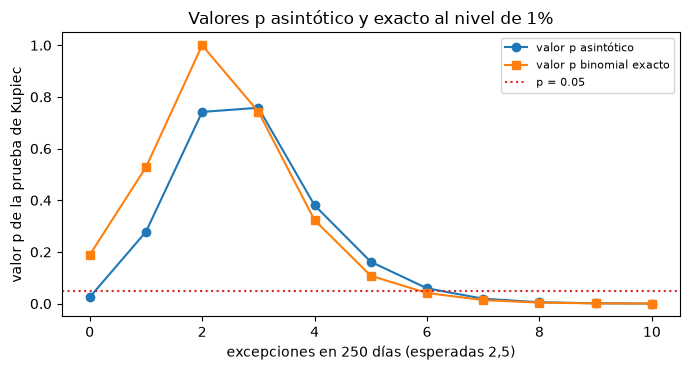

In [4]:
# Valor p asintótico frente al exacto de la prueba de Kupiec para cada conteo de 0 a 10 en 250 días al nivel
# de 1%
counts = np.arange(11)
results = [kupiec_pof(np.arange(250) < c, 0.01) for c in counts]
asymptotic = np.array([r.p_value for r in results])
exact = np.array([r.metric for r in results])
for c in (0, 6):
    print(f"x {c}: p asintótico {asymptotic[c]:.4f} | p exacto {exact[c]:.4f} | luz {LIGHT[results[c].light.value]}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(counts, asymptotic, marker="o", label="valor p asintótico")
ax.plot(counts, exact, marker="s", label="valor p binomial exacto")
ax.axhline(0.05, color="tab:red", linestyle=":", label="p = 0.05")
ax.set_xlabel("excepciones en 250 días (esperadas 2,5)")
ax.set_ylabel("valor p de la prueba de Kupiec")
ax.set_title("Valores p asintótico y exacto al nivel de 1%")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las dos curvas cruzan la línea de 0,05 en conteos distintos. Sin ninguna excepción el valor p asintótico es 0,0250 y la compuerta colorea el pronóstico de rojo, pero el valor p exacto es 0,1889: con 2,5 excepciones esperadas, no ver ninguna es una evidencia débil contra el modelo. Con 6 excepciones el valor p asintótico es 0,0594 (ámbar) y el exacto 0,0412, al otro lado de la línea. Lo quebrado de la curva exacta es real, pues un conteo binomial solo toma valores enteros. La figura muestra que el valor p asintótico puede acusar a un pronóstico correcto y absolver a uno errado cuando el conteo esperado es pequeño, de modo que el valor p exacto es el que hay que leer a su lado siempre que el conteo esperado sea menor que unos diez.

### Paso 3: la independencia y la cobertura condicional de Christoffersen

Un modelo puede tener el número correcto de excepciones y aun así estar equivocado si llegan en racimos. Christoffersen (1998) contrasta la secuencia de excepciones contra una cadena de Markov de primer orden. Sea $n_{ij}$ el número de días en que el estado $i$ fue seguido por el estado $j$ ($0$ sin excepción, $1$ excepción), $\pi_{01} = n_{01}/(n_{00}+n_{01})$, $\pi_{11} = n_{11}/(n_{10}+n_{11})$ y $\pi = (n_{01}+n_{11})/(n_{00}+n_{01}+n_{10}+n_{11})$:

$$LR_{ind} = -2\ln\frac{(1-\pi)^{n_{00}+n_{10}}\,\pi^{n_{01}+n_{11}}}{(1-\pi_{01})^{n_{00}}\,\pi_{01}^{n_{01}}\,(1-\pi_{11})^{n_{10}}\,\pi_{11}^{n_{11}}} \xrightarrow{d} \chi^2_1, \qquad LR_{cc} = LR_{POF} + LR_{ind} \xrightarrow{d} \chi^2_2$$

La independencia se cumple cuando $\pi_{01} = \pi_{11}$: una excepción no cambia la probabilidad de otra mañana. La celda cuenta las transiciones de las banderas de `garch-t` en la crisis al 2,5 por ciento, calcula los estadísticos a mano y los compara con `christoffersen_independence` y `christoffersen_conditional_coverage`.

In [5]:
# Conteo de transiciones y estadísticos de Christoffersen a mano y con el motor, para garch-t en la crisis
# al 2,5%
from riskvalidation.validation.market import christoffersen_conditional_coverage, christoffersen_independence

alpha = 0.025
flags, var = series_of("equity-2007-09", "garch-t", alpha)
before, after = flags[:-1], flags[1:]
n00, n01 = int(np.sum(~before & ~after)), int(np.sum(~before & after))
n10, n11 = int(np.sum(before & ~after)), int(np.sum(before & after))
pi01, pi11 = n01 / (n00 + n01), n11 / (n10 + n11)
pi = (n01 + n11) / (n00 + n01 + n10 + n11)
print(f"transiciones: n00 {n00}, n01 {n01}, n10 {n10}, n11 {n11}")
print(f"P(1 | 0) {pi01:.4f} | P(1 | 1) {pi11:.4f} | incondicional {pi:.4f}")
null = special.xlogy(n00 + n10, 1 - pi) + special.xlogy(n01 + n11, pi)
alternative = special.xlogy(n00, 1 - pi01) + special.xlogy(n01, pi01)
alternative += special.xlogy(n10, 1 - pi11) + special.xlogy(n11, pi11)
lr_ind = -2.0 * (null - alternative)
print(f"a mano: LR_ind {lr_ind:.4f} | p {stats.chi2.sf(lr_ind, 1):.4f}")
ind = christoffersen_independence(flags, alpha, model_id="garch-t")
cc = christoffersen_conditional_coverage(flags, alpha, model_id="garch-t")
print(f"motor: LR_ind {ind.statistic:.4f} p {ind.p_value:.4f} {LIGHT[ind.light.value]}")
print(f"cobertura condicional: LR_cc {cc.statistic:.4f} = {cc.extras['lr_pof']:.4f} + {cc.extras['lr_ind']:.4f}")

transiciones: n00 441, n01 31, n10 31, n11 0
P(1 | 0) 0.0657 | P(1 | 1) 0.0000 | incondicional 0.0616
a mano: LR_ind 4.0750 | p 0.0435
motor: LR_ind 4.0750 p 0.0435 rojo
cobertura condicional: LR_cc 23.7907 = 19.7157 + 4.0750


Para `garch-t` en la crisis al 2,5 por ciento hay 31 días con una excepción y ninguno fue seguido por otro al día siguiente: $P(1\mid 1)$ es 0,0000 frente a $P(1\mid 0)$ de 0,0657. El estadístico de independencia es 4,0750 (p 0,0435, rojo), y la cobertura condicional se descompone como 23,7907 = 19,7157 + 4,0750, de modo que la mayor parte del rechazo viene del conteo y la parte de independencia es pequeña. El rechazo de la independencia aquí es lo opuesto de un agrupamiento: excepciones que nunca caen en días consecutivos. La prueba mira solo un paso hacia adelante y no puede decir si los intervalos más largos son irregulares, que es lo que mira la prueba de duración del paso siguiente.

### Paso 4: la prueba de duración

La prueba de independencia mira solo un día hacia adelante. Christoffersen y Pelletier (2004) miran las **duraciones** $D_i$, los días entre excepciones consecutivas. Si la cobertura es correcta y las excepciones son independientes, las duraciones no tienen memoria (geométricas, cercanas a la exponencial), y la probabilidad de una excepción no depende del tiempo desde la última. Modelan la tasa instantánea como Weibull, $\lambda(d) = a^b\,b\,d^{\,b-1}$, con $b = 1$ bajo la nula, de modo que $b < 1$ es una tasa decreciente (agrupamiento) y $b > 1$ una creciente (demasiado regular). El estadístico es la razón de verosimilitud de $b = 1$, con el primer y el último tramo censurados, y su valor p es por Monte Carlo (sorteos de secuencias Bernoulli($\alpha$) del mismo largo). La celda lista las duraciones completas de `hs-250` en la crisis al 1 por ciento, corre `duration_test` con 10.000 sorteos y una semilla fija, y dibuja las duraciones frente al histograma geométrico que predice la nula.

excepciones 19 | duraciones completas 18 | media 19.1 días | esperada bajo la nula 100
LR 5.1768 | Weibull b 0.690 | p 0.0824
luz: ámbar


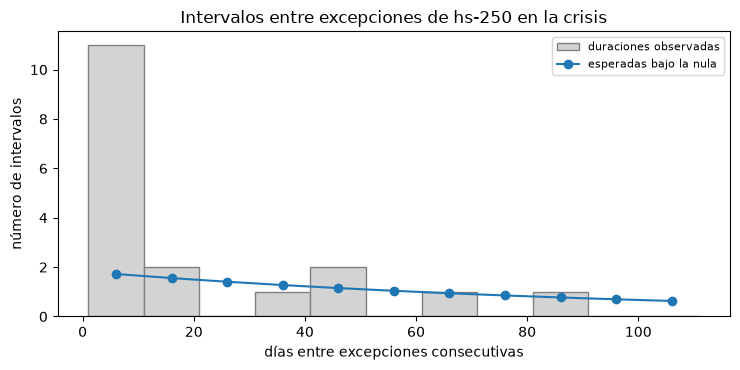

In [6]:
# Duraciones entre excepciones, la prueba de duración con 10.000 sorteos y el histograma geométrico que
# predice la nula
from riskvalidation.validation.market import duration_test

alpha = 0.01
flags, var = series_of("equity-2007-09", "hs-250", alpha)
durations = np.diff(np.flatnonzero(flags))
result = duration_test(flags, alpha, model_id="hs-250", n_mc=10000, seed=42)
print(f"excepciones {flags.sum()} | duraciones completas {durations.size} | "
      f"media {durations.mean():.1f} días | esperada bajo la nula {1 / alpha:.0f}")
print(f"LR {result.statistic:.4f} | Weibull b {result.extras['weibull_b']:.3f} | p {result.p_value:.4f}")
print(f"luz: {LIGHT[result.light.value]}")

edges = np.arange(1, 112, 10)
expected = durations.size * ((1 - alpha) ** (edges[:-1] - 1) - (1 - alpha) ** (edges[1:] - 1))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(durations, bins=edges, color="lightgrey", edgecolor="grey", label="duraciones observadas")
ax.plot((edges[:-1] + edges[1:]) / 2, expected, marker="o", color="tab:blue", label="esperadas bajo la nula")
ax.set_xlabel("días entre excepciones consecutivas")
ax.set_ylabel("número de intervalos")
ax.set_title("Intervalos entre excepciones de hs-250 en la crisis")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las barras grises son los intervalos entre las 19 excepciones de `hs-250` en la crisis y la línea azul es lo que daría un pronóstico correcto con excepciones independientes, cerca de 1,7 intervalos en cada tramo de 10 días. Once de los 18 intervalos caen dentro de los primeros 10 días, un agrupamiento que la ley geométrica no espera, mientras que el intervalo medio es de 19,1 días donde la nula espera 100. La forma de Weibull es 0,690 (bajo 1: una tasa decreciente), el estadístico 5,1768 y el valor p de Monte Carlo 0,0824, ámbar. El mismo pronóstico tiene un valor p de Kupiec de 1,705e-06 y aquí es solo ámbar: las pruebas responden preguntas distintas, y con 18 intervalos la prueba de duración tiene poca potencia.

### Paso 5: la prueba de cuantil dinámico

Engle y Manganelli (2004) preguntan si las excepciones son **predecibles** a partir de algo conocido el día anterior. Se regresa el acierto demediado $\mathrm{Hit}_t = I_t - \alpha$ sobre una constante, cuatro aciertos rezagados y el VaR actual, reunidos en la matriz $X$. Bajo cobertura condicional correcta ningún coeficiente difiere de cero, y la forma cuadrática

$$DQ = \frac{\mathrm{Hit}^{\top} X\,(X^{\top}X)^{+}\,X^{\top}\mathrm{Hit}}{\alpha(1-\alpha)}$$

es asintóticamente chi-cuadrado con grados de libertad iguales al rango de $X$. Con aciertos escasos esa ley es mala: el motor registra que la prueba simple rechazó pronósticos correctos mucho más que el 5 por ciento, así que su luz sigue un **valor p de Monte Carlo** y el asintótico queda en `extras`. La celda calcula la forma cuadrática a mano desde la definición sobre las banderas de `hs-250` y la compara con el estadístico y los valores p del motor.

In [7]:
# El estadístico de cuantil dinámico a mano (4 rezagos) y el del motor con sus valores p de Monte Carlo y
# asintótico
from riskvalidation.validation.market import dynamic_quantile_test

lags = 4
hits = flags.astype(float)
lagged = [hits[lags - j:hits.size - j] for j in range(1, lags + 1)]
X = np.column_stack([np.ones(hits.size - lags)] + lagged + [var[lags:]])
hit_demeaned = hits[lags:] - alpha
dq_by_hand = float(hit_demeaned @ X @ np.linalg.pinv(X.T @ X) @ X.T @ hit_demeaned) / (alpha * (1 - alpha))
print(f"regresión: {X.shape[0]} días, {X.shape[1]} columnas, rango {np.linalg.matrix_rank(X)}")
print(f"a mano: DQ {dq_by_hand:.4f}")
engine = dynamic_quantile_test(flags, var, alpha, lags=lags, model_id="hs-250", n_mc=10000, seed=42)
print(f"motor: DQ {engine.statistic:.4f} | p Monte Carlo {engine.p_value:.4f} | "
      f"p asintótico {engine.extras['p_value_asymptotic']:.4f} | {LIGHT[engine.light.value]}")

regresión: 500 días, 6 columnas, rango 6
a mano: DQ 121.1612
motor: DQ 121.1612 | p Monte Carlo 0.0003 | p asintótico 0.0000 | rojo


### Paso 6: el semáforo de Basilea

El marco de Basilea de 1996 juzga el VaR al 99 por ciento de un banco por el número de excepciones $k$ en los últimos 250 días hábiles. Bajo un modelo correcto $k \sim$ binomial(250; 0,01), y las zonas se cortan sobre la probabilidad acumulada $P(X \le k)$: **verde** bajo el conteo en que llega por primera vez a 95 por ciento, **ámbar** desde ahí, **roja** desde el conteo en que llega a 99,99 por ciento. El multiplicador $m_c$ del cargo de capital sube con la zona (MAR32.9 Tabla 1). El motor tiene las tres piezas como funciones: `binomial_cumulative_probability`, `traffic_light_zone` y `mar32_multiplier`. La celda las evalúa para 0 a 12 excepciones y dibuja la probabilidad acumulada coloreada por zona junto al multiplicador. El multiplicador es el $m_c$ dependiente de la prueba retrospectiva de MAR32.9, de 1,50 a 2,00; el documento versionado de la escalera lista a su lado el factor estadounidense anterior de 3,00 a 4,00.

k 4: P(X <= k) 89.2188% | zona verde | multiplicador 1.50
k 5: P(X <= k) 95.8817% | zona ámbar | multiplicador 1.70
k 9: P(X <= k) 99.9750% | zona ámbar | multiplicador 1.92
k 10: P(X <= k) 99.9946% | zona rojo | multiplicador 2.00


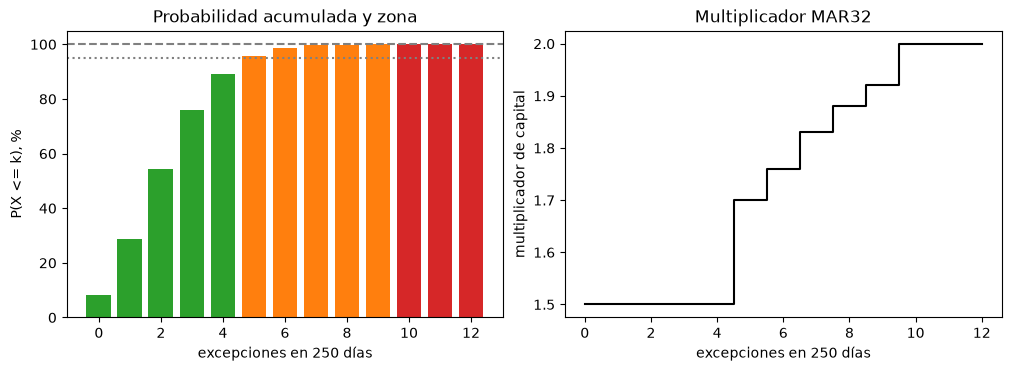

In [8]:
# La tabla del semáforo para 0 a 12 excepciones en 250 días con cobertura de 99%: probabilidad acumulada,
# zona y multiplicador
from riskvalidation.market.frtb import binomial_cumulative_probability, mar32_multiplier, traffic_light_zone

ks = np.arange(13)
cumulative = np.array([binomial_cumulative_probability(int(k), 250, 0.01) for k in ks])
zones = [traffic_light_zone(int(k)) for k in ks]
multiplier = np.array([mar32_multiplier(int(k)) for k in ks])
for k in (4, 5, 9, 10):
    print(f"k {k}: P(X <= k) {100 * cumulative[k]:.4f}% | zona {LIGHT[zones[k]]} | multiplicador {multiplier[k]:.2f}")

colour = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
left.bar(ks, 100 * cumulative, color=[colour[z] for z in zones])
left.axhline(95, color="grey", linestyle=":")
left.axhline(99.99, color="grey", linestyle="--")
left.set_xlabel("excepciones en 250 días")
left.set_ylabel("P(X <= k), %")
left.set_title("Probabilidad acumulada y zona")
right.step(ks, multiplier, where="mid", color="black")
right.set_xlabel("excepciones en 250 días")
right.set_ylabel("multiplicador de capital")
right.set_title("Multiplicador MAR32")
plt.show()

Hasta 4 excepciones la probabilidad acumulada está bajo 95 por ciento (89,2188 por ciento en 4) y la zona es verde con un multiplicador de 1,50. En 5 excepciones llega a 95,8817 por ciento y la zona pasa a ámbar con un multiplicador de 1,70; en 9 es 99,9750 por ciento y 1,92; desde 10 excepciones (99,9946 por ciento) la zona es roja y el multiplicador 2,00. La línea de puntos marca 95 por ciento y la de trazos 99,99 por ciento. La figura muestra que las zonas son probabilidades bajo la nula y no un conteo elegido por criterio, y que el multiplicador sube con suavidad por la zona ámbar antes de saturarse. No dice qué debe hacer un banco con un resultado ámbar: esa es una decisión supervisora fuera del motor.

El semáforo es función de los últimos 250 días, así que sobre una ventana más larga se puede calcular en cada ventana móvil. La celda siguiente cuenta, para `hs-250` y `ewma` en la crisis, las excepciones de cada ventana móvil de 250 días, asigna a cada ventana su zona con `traffic_light_zone` y pide a `basel_traffic_light` del motor la luz de la última ventana. La figura dibuja el conteo móvil frente a las bandas ámbar y roja.

hs-250: 255 ventanas | máximo 14 | ámbar 60, rojo 195, verde 0
  última ventana: 10 | P 99.9946% | rojo
ewma: 255 ventanas | máximo 12 | ámbar 229, rojo 26, verde 0
  última ventana: 7 | P 99.5975% | ámbar


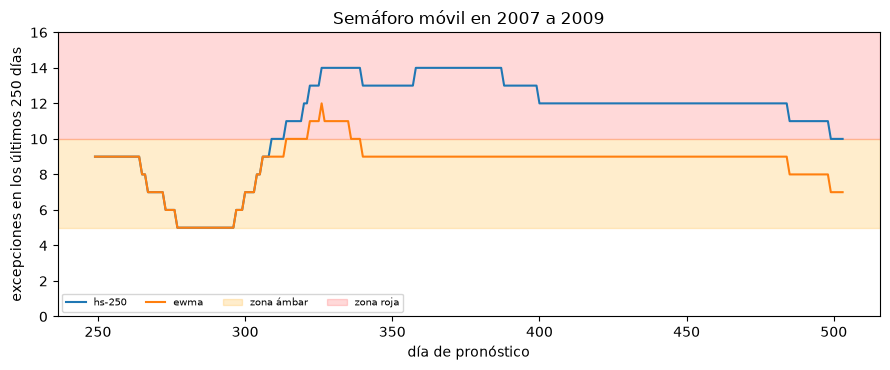

In [9]:
# Conteos móviles de excepciones de 250 días de hs-250 y ewma en la crisis, sus zonas y la luz del motor en
# la última ventana
from riskvalidation.validation.market import basel_traffic_light

fig, ax = plt.subplots(figsize=(9, 3.8))
for model_id in ("hs-250", "ewma"):
    flags, var = series_of("equity-2007-09", model_id, 0.01)
    running = np.concatenate([[0], np.cumsum(flags)])
    rolling = (running[250:] - running[:-250]).astype(int)
    zone_of = [traffic_light_zone(int(k)) for k in rolling]
    light = basel_traffic_light(flags, model_id=model_id)
    ax.plot(np.arange(rolling.size) + 249, rolling, label=model_id)
    print(f"{model_id}: {rolling.size} ventanas | máximo {rolling.max()} | "
          f"ámbar {zone_of.count('amber')}, rojo {zone_of.count('red')}, verde {zone_of.count('green')}")
    print(f"  última ventana: {int(light.statistic)} | P {light.metric:.4f}% | {LIGHT[light.light.value]}")
ax.axhspan(5, 10, color="orange", alpha=0.2, label="zona ámbar")
ax.axhspan(10, 20, color="red", alpha=0.15, label="zona roja")
ax.set_ylim(0, 16)
ax.set_xlabel("día de pronóstico")
ax.set_ylabel("excepciones en los últimos 250 días")
ax.set_title("Semáforo móvil en 2007 a 2009")
ax.legend(fontsize=7, ncol=4)
fig.tight_layout()
plt.show()

Los dos modelos parten la crisis en ámbar con 9 excepciones, bajan a 5 cerca del día 280 y luego suben. La simulación histórica `hs-250` entra a la zona roja cerca del día 310 y se queda ahí hasta el final de la ventana: de 255 ventanas móviles está en ámbar en 60 y en rojo en 195, con un máximo de 14 excepciones y 10 en la última ventana (99,9946 por ciento, rojo). EWMA toca la banda roja solo brevemente cerca del día 325 (máximo 12), está en ámbar en 229 ventanas y en rojo en 26, y termina con 7 excepciones (99,5975 por ciento, ámbar). Ninguno de los dos tiene una sola ventana verde, porque en toda ventana quedan 5 excepciones o más. La figura muestra cuánto cambia la luz un pronóstico reactivo, no que EWMA sea aceptable: el ámbar sigue llevando un multiplicador sobre el mínimo.

### Paso 7: qué ve cada prueba

Un conteo errado, excepciones agrupadas y excepciones predecibles son fallas distintas, y la batería las separa. La celda corre cuatro de las pruebas en vivo sobre los 17 modelos de la crisis de 2007 a 2009 en los dos niveles de cola (Kupiec, independencia, duración y cuantil dinámico, las dos últimas con 2.000 sorteos de Monte Carlo y una semilla fija) y cuenta cuántos modelos colorea de rojo cada prueba. La figura dibuja los conteos.

alfa 0.01: [17, 0, 2, 17] modelos en rojo, pruebas en el orden de la figura
alfa 0.025: [17, 4, 4, 17] modelos en rojo, pruebas en el orden de la figura


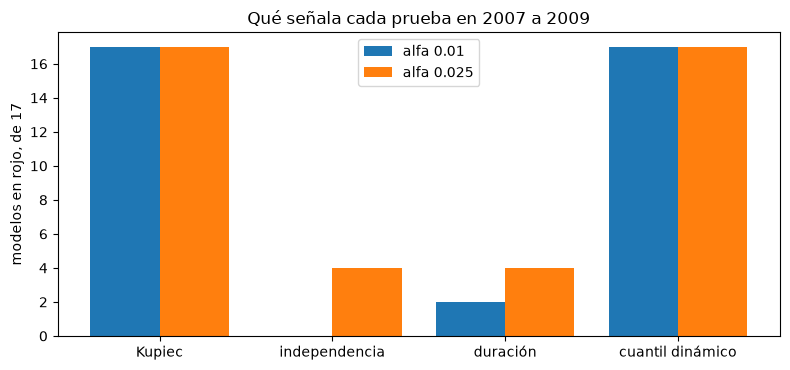

In [10]:
# Correr cuatro pruebas de excepciones sobre los 17 modelos de la crisis en los dos niveles y contar los que
# cada una marca en rojo
from riskvalidation.validation.market import dynamic_quantile_test

tests = ("Kupiec", "independencia", "duración", "cuantil dinámico")
model_ids = [m["model_id"] for m in windows["equity-2007-09"]["outputs"]["models"]]
red = np.zeros((2, len(tests)), dtype=int)
for row, alpha in enumerate((0.01, 0.025)):
    for model_id in model_ids:
        flags, var = series_of("equity-2007-09", model_id, alpha)
        lights = [
            kupiec_pof(flags, alpha, model_id).light.value,
            christoffersen_independence(flags, alpha, model_id).light.value,
            duration_test(flags, alpha, model_id, n_mc=2000, seed=42).light.value,
            dynamic_quantile_test(flags, var, alpha, lags=4, model_id=model_id, n_mc=2000, seed=42).light.value,
        ]
        red[row] += np.array(lights) == "red"
    print(f"alfa {alpha}: {red[row].tolist()} modelos en rojo, pruebas en el orden de la figura")

fig, ax = plt.subplots(figsize=(8, 3.8))
for shift, row, alpha in ((-0.2, 0, 0.01), (0.2, 1, 0.025)):
    ax.bar(np.arange(len(tests)) + shift, red[row], width=0.4, label=f"alfa {alpha}")
ax.set_xticks(np.arange(len(tests)), tests)
ax.set_ylabel("modelos en rojo, de 17")
ax.set_title("Qué señala cada prueba en 2007 a 2009")
ax.legend()
fig.tight_layout()
plt.show()

Kupiec marca en rojo a los 17 modelos en los dos niveles, y también lo hace la prueba de cuantil dinámico, que pregunta si los aciertos se pueden predecir desde su propio pasado y desde el VaR. La independencia marca a ninguno al 1 por ciento y a 4 al 2,5 por ciento, y la duración a 2 y a 4. En esta crisis la falla dominante es el número de excepciones, y las fallas de secuencia que estas pruebas pueden ver son la secundaria. La figura no muestra que el agrupamiento esté ausente: una ventana de 504 días con unas 5 excepciones esperadas da poco que trabajar a las pruebas de independencia y de duración, y por eso el motor informa sus luces como compuertas internas y no como veredictos.

## Resultados

**Respuesta:** Sobre todo porque hay demasiadas. En la crisis de 2007 a 2009 Kupiec marca en rojo a los 17 modelos en los dos niveles de cola (`hs-250` tuvo 19 excepciones en 504 días contra 5,04 esperadas, un estadístico de 22,9015 y un valor p de 1,705e-06), mientras que la independencia marca a ninguno en 0,01 y a 4 en 0,025 y la prueba de duración a 2 y a 4; la prueba de cuantil dinámico, que pregunta si los aciertos se pueden predecir, también marca 17 de 17. Juzgado por el semáforo de Basilea, `hs-250` está en rojo en 195 de sus 255 ventanas móviles, con a lo más 14 excepciones.

- **Kupiec, a mano y con el motor.** La razón de verosimilitud es 22,9015 con un valor p asintótico de 1,705e-06 y un valor p binomial exacto de 1,303e-06, y el cálculo a mano y el motor coinciden en los dígitos impresos.
- **Conteos pequeños.** En una ventana de 250 días al 1 por ciento (2,5 esperadas) cero excepciones dan un valor p asintótico de 0,0250, que la compuerta colorea de rojo, mientras que el valor p exacto es 0,1889. Con 6 excepciones el valor p asintótico es 0,0594 (ámbar) y el exacto 0,0412.
- **Independencia.** Para `garch-t` en 0,025 hay 31 días de excepción y ninguno fue seguido por otro: P(1 | 1) es 0,0000 frente a P(1 | 0) de 0,0657. El estadístico de independencia es 4,0750 (p 0,0435) y la cobertura condicional es 19,7157 + 4,0750 = 23,7907.
- **Duración.** Las 19 excepciones de `hs-250` dejan 18 intervalos completos con una media de 19,1 días donde la nula espera 100, 11 de ellos dentro de 10 días. La forma de Weibull es 0,690 y el valor p de Monte Carlo 0,0824, ámbar.
- **Cuantil dinámico.** La forma cuadrática calculada desde su definición es 121,1612 con rango 6, igual a la del motor; el valor p de Monte Carlo es 0,0003.
- **El semáforo.** Hasta 4 excepciones en 250 días la zona es verde (89,2188 por ciento de probabilidad acumulada en 4, multiplicador 1,50); de 5 a 9 es ámbar (95,8817 por ciento en 5, 99,9750 por ciento en 9, multiplicadores de 1,70 a 1,92); desde 10 (99,9946 por ciento) es roja con 2,00. En las 255 ventanas móviles `hs-250` estuvo en ámbar en 60 y en rojo en 195, y `ewma` en ámbar en 229 y en rojo en 26.
- **Qué ve cada prueba.** Los conteos de modelos en rojo, en el orden Kupiec, independencia, duración y cuantil dinámico, son 17, 0, 2 y 17 en 0,01 y 17, 4, 4 y 17 en 0,025.

Lo que este notebook no muestra: si la pérdida esperada es correcta (notebook 04) ni cuál de los modelos que pasan las compuertas es mejor (notebook 05).

## Resumen

- Toda prueba de la batería lee las banderas de excepción: una ventana cuyos retornos se retienen por licencia se puede probar desde sus días de excepción guardados.
- Kupiec prueba el conteo, la independencia y la cobertura condicional de Christoffersen prueban el orden, la prueba de duración mira los intervalos y la de cuantil dinámico pregunta si los aciertos se pueden predecir. Un modelo puede pasar una y fallar otra, así que la batería las informa por separado.
- Con 2,5 excepciones esperadas el valor p asintótico es una mala guía; lee el binomial exacto a su lado. Lo mismo vale para los valores p de Monte Carlo de las pruebas de duración y de cuantil dinámico, que el motor usa para la luz.
- El semáforo de Basilea es una probabilidad binomial acumulada cortada en 95 y 99,99 por ciento, con un multiplicador que sube por zona; calculado en cada ventana móvil muestra a un pronóstico lento en la zona roja durante la mayor parte de una crisis y a uno reactivo sobre todo en ámbar.
- Las luces de la batería de mercado del motor son compuertas internas, no umbrales regulatorios; solo las zonas y los multiplicadores del semáforo son el texto del marco.

**Qué probar después.** Repite el paso 7 sobre `rates-2022` y busca un modelo para el que la prueba de independencia sea roja mientras Kupiec es verde; luego continúa con el notebook 04, que prueba la propia pérdida esperada.

## Referencias

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Christoffersen, P. y Pelletier, D. (2004), Backtesting value-at-risk: a duration-based approach, Journal of Financial Econometrics 2(1). https://doi.org/10.1093/jjfinec/nbh004
- Engle, R. F. y Manganelli, S. (2004), CAViaR: conditional autoregressive value at risk by regression quantiles, Journal of Business and Economic Statistics 22(4). https://doi.org/10.1198/073500104000000370
- Comité de Supervisión Bancaria de Basilea (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Marco de Basilea, MAR32.9 Tabla 1 (el multiplicador) y MAR99 (el diseño de las zonas), tal como los implementa `riskvalidation.market.frtb` del motor.